# Pronóstico del ITAEE de Jalisco: estimación y combinaciones

**Objetivo.** Pronosticar el ITAEE de Jalisco a 4 trimestres con cinco modelos y combinar sus pronósticos.

1. **Estimación:** suavización exponencial, regresión lineal y ARIMA (los dos últimos con EMEC mayoreo, EMEC menudeo y EMIM como exógenas, en versión *promedio* y *último mes* del trimestre).
2. **Combinaciones:** promedio simple, ponderado por error de validación y ponderado por BIC.


> La sección 4 (validación cruzada) tarda unos 2 minutos.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import modelos as M, evaluacion as E
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

COL = {"ETS": "#2a78d6", "REG_PROM": "#17a398", "REG_ULT": "#8a63d2", "ARIMAX_PROM": "#e3a008", "ARIMAX_ULT": "#c2410c",
       "COMB_SIMPLE": "#64748b", "COMB_VARIANZA": "#e34948", "COMB_BIC": "#db2777"}
INDIV = ["ETS", "REG_PROM", "REG_ULT", "ARIMAX_PROM", "ARIMAX_ULT"]; COMB = ["COMB_SIMPLE", "COMB_VARIANZA", "COMB_BIC"]

## 1. Los datos

La tabla trimestral trae el ITAEE (índice de volumen físico, 2018 = 100) y las exógenas en dos versiones: `_prom` (promedio de los 3 meses) y `_ultimo_mes`.

Las exógenas empiezan en 2018 porque la EMIM real solo existe desde ese año; por eso los modelos con exógenas usan pocas observaciones.

In [2]:
d = M.cargar(RAIZ / "datos" / "series_macro_jalisco_trimestral.csv")
y = d["itaee_jalisco"].dropna()
d = d.loc[:y.index[-1]]          # las exógenas no pueden ir más allá del último ITAEE
print("ITAEE:", y.index[0], "→", y.index[-1], f"({len(y)} trimestres)")
d.loc["2018Q1":].tail(8)

ITAEE: 2003Q1 → 2026Q2 (94 trimestres)


,itaee_jalisco,emec_mayoreo_prom,emec_mayoreo_ultimo_mes,emec_menudeo_prom,emec_menudeo_ultimo_mes,emim_ventas_real_idx_prom,emim_ventas_real_idx_ultimo_mes
trimestre,,,,,,,
2024Q3,105.476,101.832,98.084,113.758,110.797,103.476,100.944
2024Q4,109.117,103.864,105.153,128.151,141.222,103.664,102.891
2025Q1,105.120,93.479,97.675,111.856,114.763,103.895,106.985
2025Q2,106.320,94.790,94.737,116.038,115.731,100.582,99.767
2025Q3,107.391,99.204,99.843,116.412,114.033,102.589,103.580
2025Q4,110.562,102.518,105.786,133.333,146.601,101.499,99.500
2026Q1,103.518,96.054,104.610,115.670,118.966,101.085,105.197
2026Q2,108.849,102.799,104.289,119.823,119.811,99.139,99.906


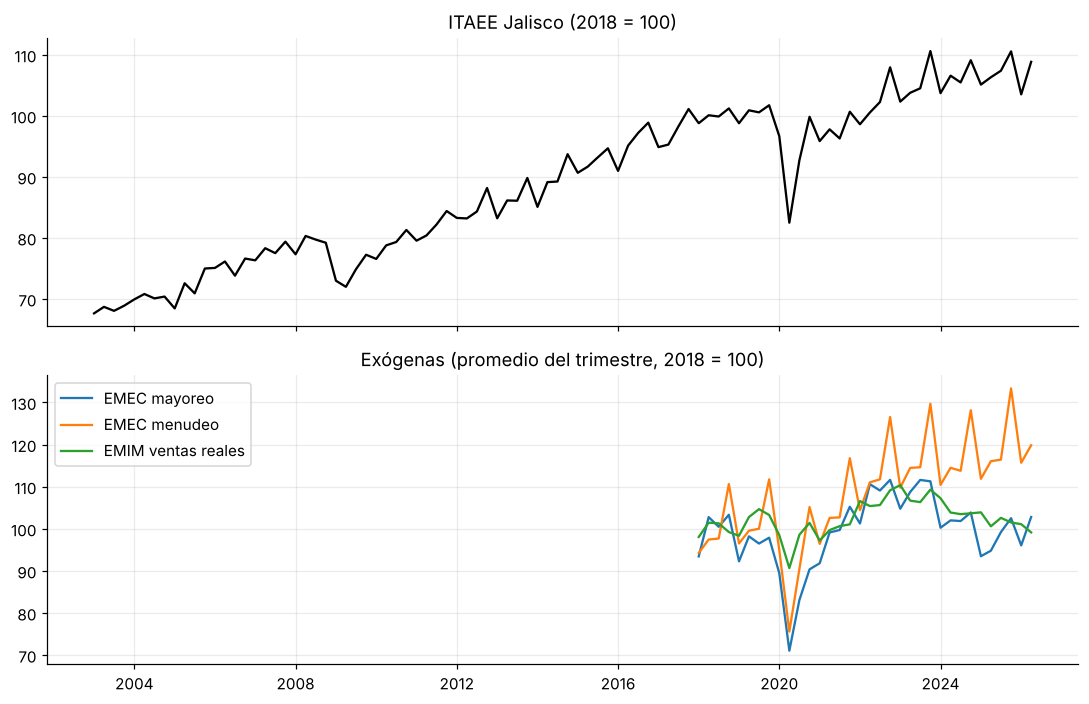

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
ax[0].plot(y.index.to_timestamp(), y, color="k"); ax[0].set_title("ITAEE Jalisco (2018 = 100)")
z = d.loc["2018Q1":]
for c, n in [("emec_mayoreo_prom", "EMEC mayoreo"), ("emec_menudeo_prom", "EMEC menudeo"), ("emim_ventas_real_idx_prom", "EMIM ventas reales")]:
    ax[1].plot(z.index.to_timestamp(), z[c], label=n)
ax[1].set_title("Exógenas (promedio del trimestre, 2018 = 100)"); ax[1].legend(); plt.tight_layout(); plt.show()

## 2. Estimación: un modelo a la vez

Todos trabajan sobre **log(ITAEE)** (estabiliza la varianza y hace que los efectos sean porcentuales) y se regresan a nivel para reportar.

### 2.1 Suavización exponencial (ETS)
Error aditivo y estacionalidad aditiva de 4 trimestres. Se compara **sin tendencia** contra **tendencia amortiguada** y se elige por AIC. No usa exógenas.

In [4]:
ets = M.ets_fit(np.log(y.values))
print("Tendencia amortiguada:", ets.model.damped_trend, "| AIC:", round(ets.aic, 2))
print(ets.summary().tables[1])

Tendencia amortiguada: True | AIC: -384.91
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
smoothing_level        0.6612      0.121      5.453      0.000       0.424       0.899
smoothing_trend     6.612e-05        nan        nan        nan         nan         nan
smoothing_seasonal  3.388e-05        nan        nan        nan         nan         nan
damping_trend          0.9800      0.009    114.186      0.000       0.963       0.997
initial_level          4.2010        nan        nan        nan         nan         nan
initial_trend          0.0095      0.005      1.803      0.071      -0.001       0.020
initial_seasonal.0     0.0384        nan        nan        nan         nan         nan
initial_seasonal.1     0.0118        nan        nan        nan         nan         nan
initial_seasonal.2     0.0095        nan        nan        nan         nan         nan


### 2.2 Regresión lineal con exógenas
`log(ITAEE) ~ log(EMEC mayoreo) + log(EMEC menudeo) + log(EMIM) + dummy 2020T2`. La dummy evita que el hundimiento de la pandemia distorsione los coeficientes. Se estima con las dos versiones de las exógenas.

**Ojo:** los residuos de esta regresión están autocorrelacionados (Durbin-Watson bajo), por eso conviene leer los errores estándar con cuidado y por eso ARIMA debería hacerlo mejor.

In [5]:
def ajustar_reg(cols):
    z = d.loc[M.INICIO_EXOG:].dropna(subset=["itaee_jalisco"] + cols)
    return sm.OLS(np.log(z["itaee_jalisco"]), sm.add_constant(M._x(z, cols))).fit()

reg = {v: ajustar_reg(M.EXOG[v]) for v in ["PROM", "ULT"]}
print("=== Promedio del trimestre ==="); print(reg["PROM"].summary().tables[1]); print("R² =", round(reg["PROM"].rsquared, 3), "| Durbin-Watson =", round(sm.stats.durbin_watson(reg["PROM"].resid), 2))
print("\n=== Último mes del trimestre ==="); print(reg["ULT"].summary().tables[1]); print("R² =", round(reg["ULT"].rsquared, 3), "| Durbin-Watson =", round(sm.stats.durbin_watson(reg["ULT"].resid), 2))

=== Promedio del trimestre ===
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                         2.5643      0.490      5.235      0.000       1.563       3.566
emec_mayoreo_prom            -0.0454      0.077     -0.589      0.561      -0.203       0.112
emec_menudeo_prom             0.4052      0.046      8.718      0.000       0.310       0.500
emim_ventas_real_idx_prom     0.0802      0.140      0.573      0.571      -0.206       0.366
covid                        -0.0718      0.026     -2.747      0.010      -0.125      -0.018
R² = 0.895 | Durbin-Watson = 0.74

=== Último mes del trimestre ===
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                               3.1571 

### 2.3 ARIMA estacional con exógenas
Mismas variables, pero los errores siguen un proceso ARIMA estacional (`s = 4`). Se prueba una rejilla pequeña de órdenes y se elige el de menor **BIC**. En la tabla, `x1`, `x2`, `x3` son EMEC mayoreo, EMEC menudeo y EMIM, y `x4` es la dummy de 2020T2.

In [6]:
arimax = {}
for v in ["PROM", "ULT"]:
    _, _, orden = M.modelo_arimax(d, M.EXOG[v], M.H)
    z = d.loc[M.INICIO_EXOG:].dropna(subset=["itaee_jalisco"] + M.EXOG[v])
    p, dd, q, P, D = orden
    arimax[v] = SARIMAX(np.log(z["itaee_jalisco"]).values, exog=M._x(z, M.EXOG[v]).values, order=(p, dd, q), seasonal_order=(P, D, 0, 4),
                        trend="c" if dd == 0 and D == 0 else "n").fit(disp=False, maxiter=200)
    print(f"{v}: order=({p},{dd},{q}) seasonal=({P},{D},0,4)  BIC={arimax[v].bic:.1f}")
print(arimax["PROM"].summary().tables[1])

PROM: order=(1,0,0) seasonal=(0,0,0,4)  BIC=-172.9


ULT: order=(0,1,1) seasonal=(0,0,0,4)  BIC=-153.7
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.6261      0.537      1.165      0.244      -0.427       1.679
x1             0.0476      0.088      0.542      0.588      -0.125       0.220
x2             0.3130      0.058      5.351      0.000       0.198       0.428
x3             0.1173      0.151      0.776      0.438      -0.179       0.414
x4            -0.0557      0.018     -3.173      0.002      -0.090      -0.021
ar.L1          0.7391      0.184      4.013      0.000       0.378       1.100
sigma2         0.0002    4.8e-05      3.566      0.000    7.71e-05       0.000


### 2.4 Qué tan bien ajusta cada uno dentro de la muestra
Ajuste ≠ capacidad de pronosticar (eso se mide en la sección 4), pero sirve para ver si algún modelo se equivoca de forma sistemática.

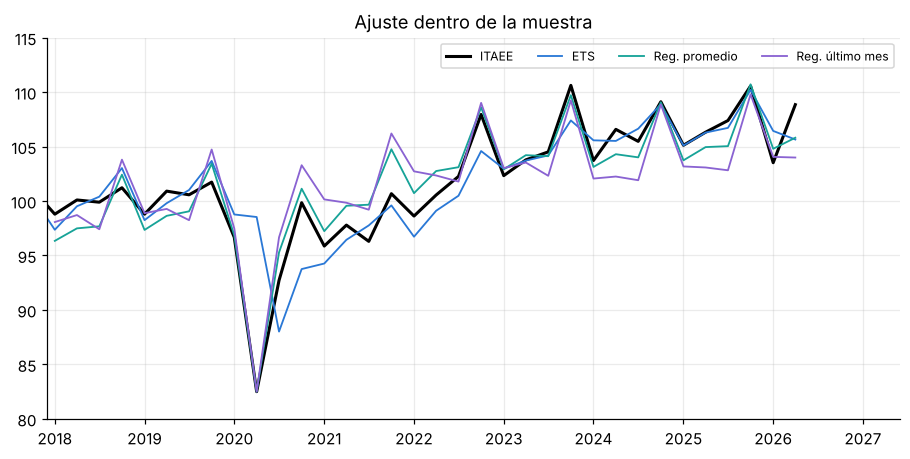

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(y.index.to_timestamp(), y, color="k", lw=2, label="ITAEE")
ax.plot(y.index.to_timestamp(), np.exp(ets.fittedvalues), color=COL["ETS"], lw=1.2, label="ETS")
for v, nom in [("PROM", "Reg. promedio"), ("ULT", "Reg. último mes")]:
    f = np.exp(reg[v].fittedvalues); ax.plot(f.index.to_timestamp(), f, color=COL["REG_" + v], lw=1.2, label=nom)
ax.set_xlim(pd.Timestamp("2017-12-01"), None); ax.set_ylim(80, 115); ax.legend(ncol=4, fontsize=8); ax.set_title("Ajuste dentro de la muestra"); plt.show()

### 2.5 Pronóstico a 4 trimestres de cada modelo
Las exógenas no se conocen en el futuro, así que primero **se pronostican con suavización exponencial** y esos valores entran a la regresión y al ARIMA. (Después se puede cambiar, por ejemplo usando los datos mensuales ya publicados del trimestre en curso.)

In [8]:
res = M.ajustar_y_pronosticar(d)                       # {modelo: (pronóstico, BIC, detalle)}
idx = pd.period_range(y.index[-1] + 1, periods=M.H, freq="Q")
pron = pd.DataFrame({m: res[m][0] for m in INDIV}, index=idx)
bic = {m: res[m][1] for m in INDIV}
print("BIC (ventana común de 20 residuos):", {m: round(float(b), 1) for m, b in bic.items()})
pron

BIC (ventana común de 20 residuos): {'ETS': -134.4, 'REG_PROM': -143.0, 'REG_ULT': -125.9, 'ARIMAX_PROM': -152.4, 'ARIMAX_ULT': -145.0}


,ETS,REG_PROM,REG_ULT,ARIMAX_PROM,ARIMAX_ULT
2026Q3,108.156,106.196,103.463,108.527,106.933
2026Q4,111.219,111.402,110.305,112.228,111.527
2027Q1,107.173,105.424,104.486,106.361,107.233
2027Q2,108.342,105.467,103.952,106.167,107.436


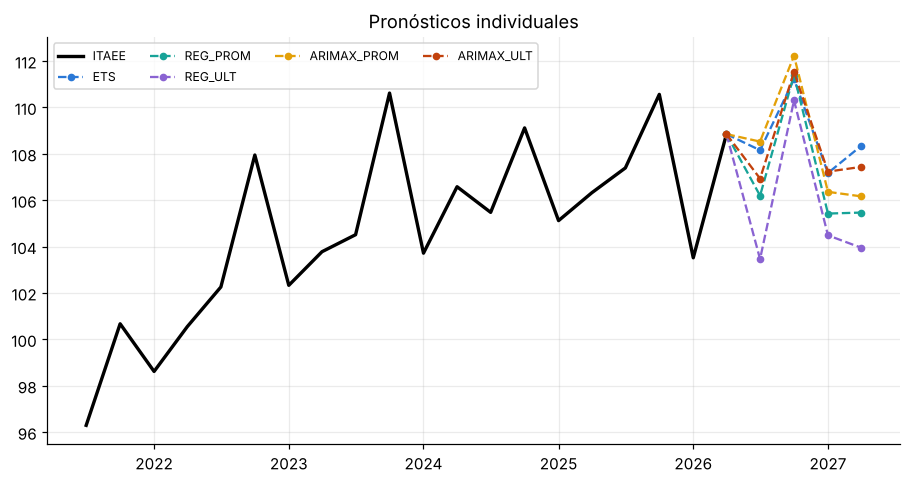

In [9]:
def grafica(cols, titulo, ultimos=20):
    fig, ax = plt.subplots(figsize=(10, 4.8)); h = y.iloc[-ultimos:]
    ax.plot(h.index.to_timestamp(), h, color="k", lw=2.2, label="ITAEE")
    for m in cols:
        s = pd.concat([y.iloc[[-1]], pron[m]]); ax.plot(s.index.to_timestamp(), s, "o--" if m in INDIV else "o-", color=COL[m], lw=2.4 if m in COMB else 1.5, ms=4, label=m)
    ax.set_title(titulo); ax.legend(ncol=4, fontsize=8); plt.show()

grafica(INDIV, "Pronósticos individuales")

## 3. Validación cruzada: ¿cuál pronostica mejor?

Para decidir los pesos no basta con ver el ajuste. Se hace una **ventana expansiva**: se estima con datos hasta un trimestre *T* (desde 2022T4), se pronostica *T+1…T+4* y se compara con lo que realmente pasó. Así cada modelo se evalúa solo con pronósticos *que nunca vio*.

Medidas (como en la presentación): ME, MAE, RMSE, MPE, MAPE, MASE, ACF1 y **U de Theil** (menor a 1 = mejor que repetir el último valor). Errores = real − pronóstico.

In [10]:
cv, info = M.validacion_cruzada(d)
print("Pronósticos evaluados:", len(cv), "| orígenes:", cv["origen"].nunique())

Pronósticos evaluados: 250 | orígenes: 14


## 4. Combinaciones de pronósticos

Tres formas de combinar los cinco pronósticos individuales:

* **Promedio simple:** todos pesan igual (1/5).
* **Ponderado por error:** pesa más el modelo con menor error en la validación cruzada: $w_i = \dfrac{1/\mathrm{MSE}_i}{\sum_j 1/\mathrm{MSE}_j}$, calculado **por horizonte**.
* **Ponderado por BIC:** $a_i = e^{(BIC^* - BIC_i)/2}$, $w_i = a_i / \sum_j a_j$. Penaliza mucho la diferencia de BIC, por eso tiende a concentrar el peso en un solo modelo.

**Importante:** al evaluar las combinaciones *dentro* de la validación cruzada, los pesos de cada origen usan solo los errores que ya se conocían en ese momento (no se hace trampa mirando el futuro).

In [11]:
comb = E.combinaciones_cv(cv, info)
todo = pd.concat([cv, comb], ignore_index=True)
medidas = E.tabla_medidas(todo, y)

def tabla_h(h):
    t = medidas[medidas.h == h].set_index("modelo").loc[INDIV + COMB, ["n", "ME", "MAE", "RMSE", "MAPE", "MASE", "ACF1", "Theil_U"]]
    return t.style.format(precision=3).highlight_min(subset=["RMSE"], color="#cdebd4")
print("Horizonte 1 trimestre"); display(tabla_h(1))

Horizonte 1 trimestre


,n,ME,MAE,RMSE,MAPE,MASE,ACF1,Theil_U
modelo,,,,,,,,
ETS,14,0.101,1.321,1.783,1.242,0.443,-0.611,0.428
REG_PROM,14,1.850,1.994,2.476,1.858,0.669,-0.401,0.603
REG_ULT,14,3.178,3.246,3.716,3.036,1.089,-0.179,0.904
ARIMAX_PROM,14,0.531,1.596,1.975,1.498,0.535,-0.595,0.481
ARIMAX_ULT,14,0.787,1.988,2.453,1.866,0.666,-0.399,0.597
COMB_SIMPLE,14,1.289,1.766,2.190,1.652,0.592,-0.548,0.535
COMB_VARIANZA,14,0.958,1.634,2.060,1.531,0.548,-0.557,0.502
COMB_BIC,14,0.537,1.597,1.973,1.499,0.536,-0.593,0.481


In [12]:
print("Horizonte 4 trimestres"); display(tabla_h(4))

Horizonte 4 trimestres


,n,ME,MAE,RMSE,MAPE,MASE,ACF1,Theil_U
modelo,,,,,,,,
ETS,11,0.472,1.216,1.490,1.131,0.408,-0.280,0.811
REG_PROM,11,2.739,2.739,3.098,2.540,0.919,-0.518,1.685
REG_ULT,11,4.024,4.024,4.363,3.743,1.349,-0.282,2.380
ARIMAX_PROM,11,1.387,1.660,2.027,1.542,0.557,-0.402,1.107
ARIMAX_ULT,11,2.390,2.715,3.050,2.532,0.910,-0.242,1.671
COMB_SIMPLE,11,2.203,2.348,2.631,2.182,0.787,-0.456,1.436
COMB_VARIANZA,11,1.840,2.098,2.355,1.952,0.703,-0.344,1.287
COMB_BIC,11,1.387,1.660,2.026,1.543,0.557,-0.396,1.107


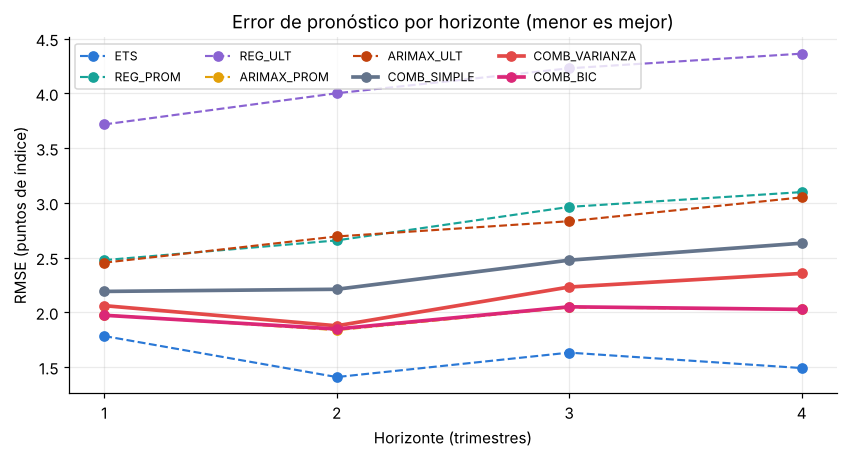

In [13]:
rmse = medidas.pivot(index="h", columns="modelo", values="RMSE")[INDIV + COMB]
fig, ax = plt.subplots(figsize=(9, 4.2))
for m in INDIV + COMB: ax.plot(rmse.index, rmse[m], "o-" if m in COMB else "o--", color=COL[m], lw=2.4 if m in COMB else 1.4, label=m)
ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("Horizonte (trimestres)"); ax.set_ylabel("RMSE (puntos de índice)"); ax.set_title("Error de pronóstico por horizonte (menor es mejor)")
ax.legend(ncol=4, fontsize=8); plt.show()

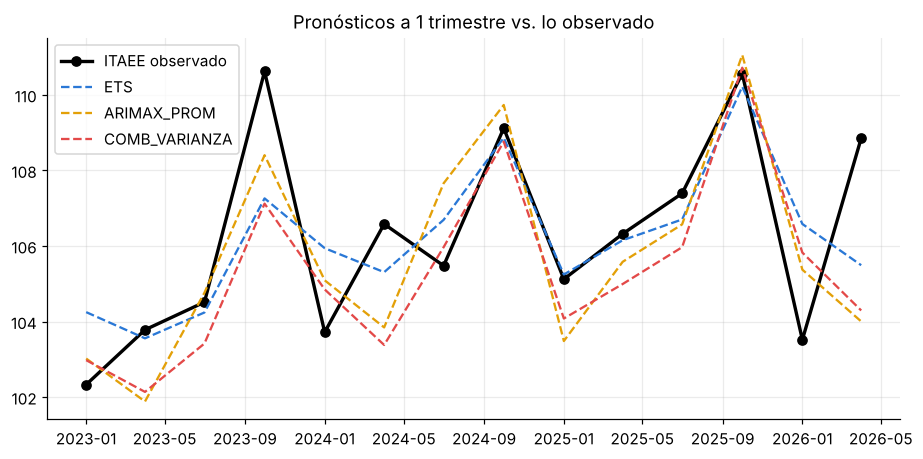

In [14]:
b = todo[todo.h == 1]
fig, ax = plt.subplots(figsize=(10, 4.5))
real = b[b.modelo == "ETS"].set_index("objetivo")["real"]; x = pd.PeriodIndex(real.index, freq="Q").to_timestamp()
ax.plot(x, real.values, "ko-", lw=2.2, label="ITAEE observado")
for m in ["ETS", "ARIMAX_PROM", "COMB_VARIANZA"]:
    ax.plot(x, b[b.modelo == m].set_index("objetivo")["pron"].values, "--", color=COL[m], label=m)
ax.set_title("Pronósticos a 1 trimestre vs. lo observado"); ax.legend(); plt.show()

### 4.1 Los pesos

,Error h=1,Error h=2,Error h=3,Error h=4,BIC,Simple
ETS,32.3%,44.1%,41.3%,47.0%,0.0%,20.0%
REG_PROM,16.8%,12.4%,12.5%,10.9%,0.9%,20.0%
REG_ULT,7.4%,5.5%,6.1%,5.5%,0.0%,20.0%
ARIMAX_PROM,26.3%,25.9%,26.3%,25.4%,96.7%,20.0%
ARIMAX_ULT,17.1%,12.1%,13.7%,11.2%,2.4%,20.0%


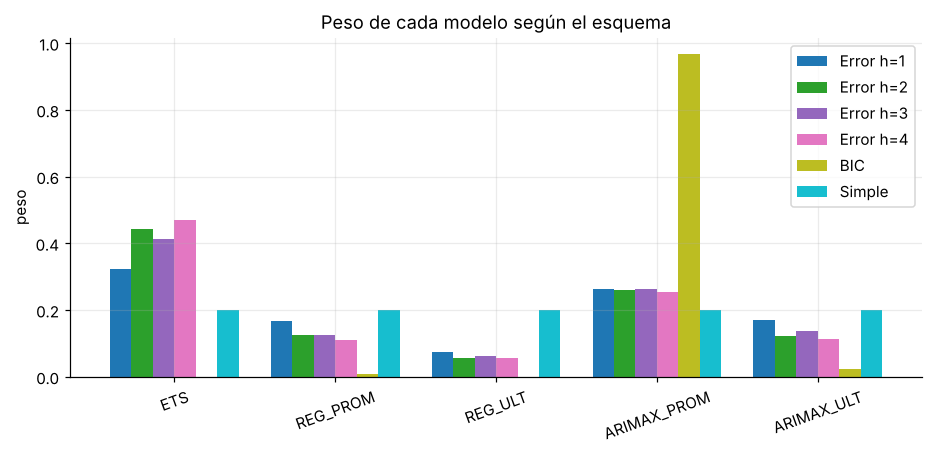

In [15]:
w_var = {}
for h in range(1, M.H + 1):
    mse = {m: float(((cv[(cv.modelo == m) & (cv.h == h)].real - cv[(cv.modelo == m) & (cv.h == h)].pron) ** 2).mean()) for m in INDIV}
    w_var[h] = E.pesos_varianza(mse)
w_bic = E.pesos_bic(bic)
pesos = pd.DataFrame({**{f"Error h={h}": w_var[h] for h in w_var}, "BIC": w_bic, "Simple": {m: 1 / 5 for m in INDIV}}).loc[INDIV]
display(pesos.style.format("{:.1%}").background_gradient(cmap="Blues", vmin=0, vmax=1))
pesos.plot.bar(figsize=(10, 4), width=.8, colormap="tab10"); plt.title("Peso de cada modelo según el esquema"); plt.ylabel("peso"); plt.xticks(rotation=20); plt.show()

### 4.2 Pronóstico final combinado

,2026Q3,2026Q4,2027Q1,2027Q2
ETS,108.16,111.22,107.17,108.34
REG_PROM,106.20,111.40,105.42,105.47
REG_ULT,103.46,110.30,104.49,103.95
ARIMAX_PROM,108.53,112.23,106.36,106.17
ARIMAX_ULT,106.93,111.53,107.23,107.44
COMB_SIMPLE,106.65,111.34,106.14,106.27
COMB_VARIANZA,107.37,111.49,106.58,107.13
COMB_BIC,108.47,112.20,106.37,106.19


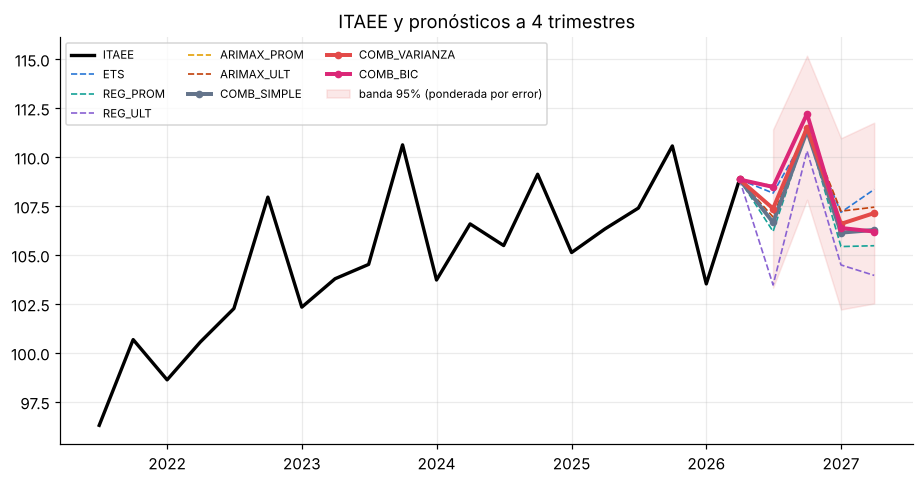

In [16]:
pron["COMB_SIMPLE"] = pron[INDIV].mean(axis=1)
pron["COMB_VARIANZA"] = [E.combinar(pron.loc[t, INDIV].to_dict(), w_var[k + 1]) for k, t in enumerate(idx)]
pron["COMB_BIC"] = [E.combinar(pron.loc[t, INDIV].to_dict(), w_bic) for t in idx]
display(pron.T.style.format("{:.2f}"))

fig, ax = plt.subplots(figsize=(10, 4.8)); h = y.iloc[-20:]
ax.plot(h.index.to_timestamp(), h, color="k", lw=2.2, label="ITAEE")
for m in INDIV + COMB:
    s = pd.concat([y.iloc[[-1]], pron[m]]); ax.plot(s.index.to_timestamp(), s, "o-" if m in COMB else "--", color=COL[m], lw=2.6 if m in COMB else 1.1, ms=4, label=m)
r = medidas[(medidas.modelo == "COMB_VARIANZA")].set_index("h")["RMSE"]
ban = 1.96 * r.reindex(range(1, 5)).values; f = pron["COMB_VARIANZA"].values; xs = idx.to_timestamp()
ax.fill_between(xs, f - ban, f + ban, color=COL["COMB_VARIANZA"], alpha=.12, label="banda 95% (ponderada por error)")
ax.set_title("ITAEE y pronósticos a 4 trimestres"); ax.legend(ncol=3, fontsize=7.5); plt.show()

## 5. conclusión:

* **La suavización exponencial es el mejor modelo individual** en validación; ninguna combinación la supera en RMSE a 1 y 4 trimestres. Combinar ayuda a reducir el riesgo de elegir mal, pero aquí no mejora el error.
* **La regresión es la más débil:** subestima de forma sistemática (ME positivo) y sus residuos están autocorrelacionados. Lo que más pesa en ella es EMEC menudeo.
* **El BIC concentra el peso en un solo modelo** (ARIMA con exógenas, promedio), así que esa combinación casi es ese modelo.
* **Pocos datos:** las exógenas empiezan en 2018, la validación tiene entre 11 y 14 orígenes por horizonte. Las diferencias pequeñas de RMSE no son concluyentes.
* **Las exógenas se pronostican con ETS**, así que los modelos con exógenas no aprovechan información que de verdad se conozca antes. Esto puede cambiar tras hablar con el profesor.
* El BIC se compara con los últimos 20 residuos de cada modelo (ventana común) para que sea comparable entre modelos con distinta muestra.

## 6. Exportar resultados para la página

Escribe `site/data/resultados.json`. Corre el notebook completo y haz push: GitHub Actions publica la página con estos resultados.

In [ ]:
# Escribe site/data/resultados.json, que es lo único que lee la página.
# Usa las variables de las secciones anteriores: y, idx, pron, bic, cv, medidas, pesos.
import json, math
from datetime import datetime, timezone

def _t(p):
    p = pd.Period(p, freq="Q"); return f"{p.year}T{p.quarter}"

def _n(x, nd=4):
    if x is None: return None
    x = float(x); return None if (math.isnan(x) or math.isinf(x)) else round(x, nd)

NOMBRES = {  # nombre largo, nombre corto en la página
    "ETS": ("Suavización exponencial (ETS)", "ETS"),
    "REG_PROM": ("Regresión · promedio", "Regresión prom."), "REG_ULT": ("Regresión · último mes", "Regresión últ."),
    "ARIMAX_PROM": ("ARIMAX · promedio", "ARIMAX prom."), "ARIMAX_ULT": ("ARIMAX · último mes", "ARIMAX últ."),
    "COMB_SIMPLE": ("Combinación simple", "Comb. simple"), "COMB_VARIANZA": ("Combinación por error", "Comb. por error"),
    "COMB_BIC": ("Combinación por BIC", "Comb. BIC"),
}
TODOS = INDIV + COMB

base_anual = []  # mismo trimestre del año anterior, para la variación anual
for t in idx:
    t4 = t - 4
    base_anual.append(_n(y.loc[t4]) if t4 in y.index else (_n(pron.loc[t4, "COMB_VARIANZA"]) if t4 in pron.index else None))

banda = 1.96 * medidas[medidas.modelo == "COMB_VARIANZA"].set_index("h")["RMSE"].reindex(range(1, M.H + 1))
cols = [c for c in ["n", "ME", "MAE", "RMSE", "MPE", "MAPE", "MASE", "ACF1", "Theil_U"] if c in medidas.columns]
rmse_h = medidas.pivot(index="h", columns="modelo", values="RMSE").reindex(range(1, M.H + 1))

resultados = {
    "meta": {
        "ejemplo": False,
        "generado": datetime.now(timezone.utc).isoformat(timespec="minutes"),
        "primer_trimestre": _t(y.index[0]), "ultimo_trimestre": _t(y.index[-1]), "n_trimestres": int(len(y)),
        "n_pronosticos_cv": int(len(cv)), "n_origenes_cv": int(cv["origen"].nunique()),
        "horizonte": int(M.H), "modelo_banda": "COMB_VARIANZA",
    },
    "modelos": [{"k": m, "label": NOMBRES.get(m, (m, m))[0], "short": NOMBRES.get(m, (m, m))[1],
                 "color": COL.get(m, "#64748b"), "comb": m in COMB} for m in TODOS],
    "historico": [{"t": _t(t), "v": _n(v, 3)} for t, v in y.items()],
    "trimestres": [_t(t) for t in idx],
    "pronosticos": {m: [_n(v, 3) for v in pron[m].values] for m in TODOS},
    "base_anual": base_anual,
    "banda": [_n(v, 3) for v in banda.values],
    "medidas": {str(h): {m: {c: _n(r[c]) for c in cols}
                         for m, r in medidas[medidas.h == h].set_index("modelo").iterrows() if m in TODOS}
                for h in range(1, M.H + 1)},
    "rmse": {m: [_n(v) for v in rmse_h[m].values] for m in TODOS if m in rmse_h.columns},
    "pesos": {"columnas": list(pesos.columns),
              "filas": {m: [_n(v * 100, 2) for v in pesos.loc[m].values] for m in pesos.index}},
    "bic": {m: _n(b, 2) for m, b in bic.items()},
}

salida = RAIZ / "site" / "data" / "resultados.json"
salida.parent.mkdir(parents=True, exist_ok=True)
salida.write_text(json.dumps(resultados, ensure_ascii=False, indent=1), encoding="utf-8")
print("Listo →", salida.relative_to(RAIZ), "| pronóstico", resultados["trimestres"][0], "–", resultados["trimestres"][-1])